# Công đoạn 07 — Đánh giá cuối cùng và dự đoán Top-3
## 1. Mục tiêu
Fit cấu hình đã chốt từ Notebook 06 đúng một lần trên 800 mẫu Train; đánh giá một phiên bản trên 200 mẫu Test. Không tuning, thử mô hình khác, chọn lại đặc trưng hay tích hợp website.

## 2. Cơ sở lý thuyết
Accuracy là tỷ lệ Top-1 đúng. Macro-F1 trung bình F1 đều giữa 33 ngành (zero_division=0). Balanced Accuracy trung bình recall theo lớp, giảm ảnh hưởng của cỡ lớp khác nhau. Hit@3 là tỷ lệ ngành thực tế thuộc ba nhãn có xác suất dự đoán cao nhất, không phải ba ngành phù hợp nhất. Confusion Matrix: hàng là nhãn thật, cột là nhãn dự đoán.

Xác suất LogisticRegression chỉ là đầu ra phân loại ngành đang học, chưa được kiểm chứng hiệu chuẩn trong nghiên cứu này và không là mức độ phù hợp nghề nghiệp. Thang Likert là thứ bậc; mã hóa số/chuẩn hóa là lựa chọn kỹ thuật, không xác nhận khoảng cách tâm lý bằng nhau.

## 3. Tái lập Train/Test
Làm sạch như Notebook 01: giữ các câu trả lời Likert văn bản hợp lệ và trim nhãn ngành. Không xóa dòng, không đổi 33 nhãn. Group theo tuple đủ 54 đáp án gốc, factorize(sort=False); StratifiedGroupKFold(5, shuffle=True, random_state=42), fold đầu tiên. Đối chiếu trực tiếp code tạo group/chia của Notebook 02 bằng AST và kiểm tra index khớp; không phụ thuộc biến kernel cũ.

Nhãn toàn tập chỉ phục vụ việc tái lập phân tầng đã cố định. Chưa tạo hoặc phân tích y_test trước fit; việc xác nhận đủ 33 ngành ở Test được hoãn đến sau fit. Không dùng Test chọn cấu hình.

In [1]:
from pathlib import Path
import sys, ast
import pandas as pd
import numpy as np
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold
import nbformat
assert sys.version_info[:2] == (3,14)
ROOT = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'data_AI_1000_rows.xlsx').is_file())
raw = pd.read_excel(ROOT/'data_AI_1000_rows.xlsx',sheet_name='AUGMENTED_RAW_1000')
metadata = ['Dấu thời gian','Tên Sinh viên','Ngành học','Giới tính']
assert raw.shape == (1000,58) and list(raw.columns[:4]) == metadata
questions = list(raw.columns[4:])
levels = ['Chưa bao giờ đúng','Chỉ đúng 1 vài trường hợp','Chỉ đúng 1 nửa','Gần như là đúng','Hoàn toàn đúng']
X = raw[questions].copy()
y = raw['Ngành học'].astype('string').str.strip()
assert X.notna().all().all() and X.isin(levels).all().all()
assert y.notna().all() and y.ne('').all() and y.nunique() == 33
assert X.shape[1] == 54 and not set(metadata).intersection(X.columns)
groups = pd.Series(pd.factorize(pd.Series(list(X.itertuples(index=False, name=None))), sort=False)[0], index=X.index)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_pos, test_pos = next(splitter.split(X, y, groups))
ref = nbformat.read(ROOT/'data/ml_pipeline/notebooks/02_chia_du_lieu.ipynb',4)
src = next(c.source for c in ref.cells if c.cell_type=='code' and 'from sklearn.model_selection import StratifiedGroupKFold' in c.source)
nodes = [node for node in ast.parse(src).body if isinstance(node,ast.Assign) and any(
    isinstance(t,ast.Name) and t.id in {'groups','splitter'} or isinstance(t,ast.Tuple) and [v.id for v in t.elts]==['train_pos','test_pos'] for t in node.targets)]
assert len(nodes)==3
check = {'pd':pd,'X':X,'y':y,'StratifiedGroupKFold':StratifiedGroupKFold}
exec(compile(ast.Module(body=nodes,type_ignores=[]),'<Notebook02 split>','exec'),check)
assert groups.equals(check['groups'])
assert np.array_equal(train_pos,check['train_pos']) and np.array_equal(test_pos,check['test_pos'])
X_train,y_train = X.iloc[train_pos].copy(),y.iloc[train_pos].copy()
assert X_train.shape==(800,54) and y_train.nunique()==33
assert len(test_pos)==200 and len(train_pos)+len(test_pos)==len(X)
assert X.index.is_unique and not set(train_pos).intersection(test_pos)
assert set(groups.iloc[train_pos]).isdisjoint(groups.iloc[test_pos])
print('PASS: index đúng Notebook 02; Train 800 x 54, 33 ngành; Test 200; không giao index/vector.')
X_test_text = X.iloc[test_pos].copy()
assert X_test_text.shape == (200,54)
assert X_train.index.intersection(X_test_text.index).empty
assert set(X_train.itertuples(index=False,name=None)).isdisjoint(X_test_text.itertuples(index=False,name=None))
assert list(X_train.columns) == list(X_test_text.columns) == questions
del raw,X,groups,check,ref


PASS: index đúng Notebook 02; Train 800 x 54, 33 ngành; Test 200; không giao index/vector.


## 4. Huấn luyện cấu hình đã chọn
StandardScaler mặc định → LogisticRegression(C=1, solver="lbfgs", max_iter=10000, tol=1e-4, random_state=42). Dùng đủ 54 câu, không thêm selector/PCA. Chỉ gọi fit một lần trên Train. Nếu không hội tụ thì dừng báo cáo, không tự đổi tham số hoặc fit lại.

In [2]:
import sklearn
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
print('Python:',sys.version,'; sklearn:',sklearn.__version__)
mapping = dict(zip(levels,range(1,6)))
X_train_numeric = X_train.apply(lambda col:col.map(mapping)).astype('int64')
X_train_numeric.columns = [f'q{i}' for i in range(1,55)]
assert X_train_numeric.shape == (800,54)
assert X_train_numeric.isin(range(1,6)).all().all()
assert X_train_numeric.index.equals(y_train.index)
assert 'y_test' not in globals()
final_pipeline = Pipeline([
    ('scaler',StandardScaler()),
    ('classifier',LogisticRegression(C=1,solver='lbfgs',max_iter=10000,tol=1e-4,random_state=42))])
with warnings.catch_warnings(record=True) as fit_warnings:
    warnings.simplefilter('always')
    final_pipeline.fit(X_train_numeric,y_train)
for warning in fit_warnings:
    print(warning.category.__name__,str(warning.message))
if any(issubclass(w.category,ConvergenceWarning) for w in fit_warnings):
    raise RuntimeError('Mô hình chưa hội tụ; dừng, không tự fit lại hoặc xem Test.')
scaler = final_pipeline.named_steps['scaler']
classifier = final_pipeline.named_steps['classifier']
assert scaler.n_samples_seen_ == 800 and scaler.n_features_in_ == 54
assert np.allclose(scaler.mean_,X_train_numeric.mean())
assert np.allclose(scaler.var_,X_train_numeric.var(ddof=0))
assert classifier.n_features_in_ == 54 and len(classifier.classes_) == 33
print('PASS: Pipeline fit một lần trên Train; scaler không fit Test.')
print(final_pipeline)
print('Tham số classifier đầy đủ:',classifier.get_params())
print('Số vòng lặp:',classifier.n_iter_)

Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)] ; sklearn: 1.9.1
PASS: Pipeline fit một lần trên Train; scaler không fit Test.
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(C=1, max_iter=10000, random_state=42))])
Tham số classifier đầy đủ: {'C': 1, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 10000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
Số vòng lặp: [44]


## 5. Đánh giá một phiên bản trên Test
Sau khi fit hoàn tất mới lấy y_test. Chỉ gọi predict và predict_proba một lần trên toàn Test rồi tái sử dụng đầu ra cho mọi bảng/biểu đồ/ví dụ. Top-3 sắp xác suất giảm dần; hòa xác suất ưu tiên cột trước theo classes_ để tái lập. Kiểm tra classes_ giữa Pipeline và classifier, đủ 33 nhãn và xác suất hợp lệ.

In [3]:
from sklearn.metrics import (accuracy_score,f1_score,balanced_accuracy_score,
                             confusion_matrix,classification_report)
y_test = y.iloc[test_pos].copy()
assert y_test.nunique() == 33 and set(y_test) == set(y_train)
assert y_test.index.equals(X_test_text.index)
X_test_numeric = X_test_text.apply(lambda col:col.map(mapping)).astype('int64')
X_test_numeric.columns = X_train_numeric.columns.copy()
assert X_test_numeric.shape == (200,54)
assert X_test_numeric.isin(range(1,6)).all().all()
assert list(X_test_numeric.columns) == list(X_train_numeric.columns)
assert X_train_numeric.index.intersection(X_test_numeric.index).empty
predictions = final_pipeline.predict(X_test_numeric)
probabilities = final_pipeline.predict_proba(X_test_numeric)
classes = np.asarray(classifier.classes_)
assert np.array_equal(classes,final_pipeline.classes_)
assert set(classes) == set(y_train) == set(y_test)
assert probabilities.shape == (200,33) and np.isfinite(probabilities).all()
assert (probabilities >= 0).all() and (probabilities <= 1).all()
assert np.allclose(probabilities.sum(axis=1),1)
ranked = np.argsort(-probabilities,axis=1,kind='stable')[:,:3]
top3_labels = classes[ranked]
top3_probabilities = np.take_along_axis(probabilities,ranked,axis=1)
assert top3_labels.shape == (200,3)
assert all(len(set(row)) == 3 for row in top3_labels)
assert np.all(top3_probabilities[:,:-1] >= top3_probabilities[:,1:])
assert np.array_equal(predictions,top3_labels[:,0])
truth = y_test.to_numpy()
top1_correct = predictions == truth
top3_correct = (top3_labels == truth[:,None]).any(axis=1)
assert (top1_correct <= top3_correct).all()
test_metrics = pd.Series({
    'Accuracy':accuracy_score(truth,predictions),
    'Macro-F1':f1_score(truth,predictions,labels=classes,average='macro',zero_division=0),
    'Balanced Accuracy':balanced_accuracy_score(truth,predictions),
    'Hit@3':top3_correct.mean()},name='Test')
assert np.isclose(test_metrics['Accuracy'],top1_correct.mean())
assert test_metrics.between(0,1).all()
display(test_metrics.to_frame().round(6))
print('Top-1 đúng:',int(top1_correct.sum()),'/ 200')
print('Top-3 chứa ngành thực tế:',int(top3_correct.sum()),'/ 200')
print('Top-3 không chứa ngành thực tế:',int((~top3_correct).sum()),'/ 200')
del y


Top-1 đúng: 26 / 200
Top-3 chứa ngành thực tế: 57 / 200
Top-3 không chứa ngành thực tế: 143 / 200


                       Test
Accuracy           0.130000
Macro-F1           0.123126
Balanced Accuracy  0.131987
Hit@3              0.285000

## 6. Confusion Matrix và kết quả đủ 33 ngành
Hàng nhãn thật, cột nhãn dự đoán. Support nhỏ khiến thay đổi chỉ một vài mẫu đã tác động lớn đến recall/F1. Không dùng metadata cá nhân để giải thích sai số.

                                    support  precision  recall  f1-score
Công nghệ kỹ thuật hóa học                6     0.5000  0.6667    0.5714
Công nghệ kỹ thuật xây dựng               5     0.1429  0.2000    0.1667
Công nghệ thông tin                      15     0.1333  0.1333    0.1333
Công tác xã hội                           5     0.0000  0.0000    0.0000
Giáo dục chính trị                        5     0.0000  0.0000    0.0000
Giáo dục mầm non                          5     0.0000  0.0000    0.0000
Giáo dục tiểu học                         9     0.0000  0.0000    0.0000
Kinh tế                                   6     0.0000  0.0000    0.0000
Kế toán                                   6     0.0000  0.0000    0.0000
Kỹ thuật phần mềm                         5     0.2000  0.2000    0.2000
Kỹ thuật điện                             5     0.4000  0.4000    0.4000
Kỹ thuật điện tử - viễn thông             5     0.0000  0.0000    0.0000
Luật                                      8     0.0

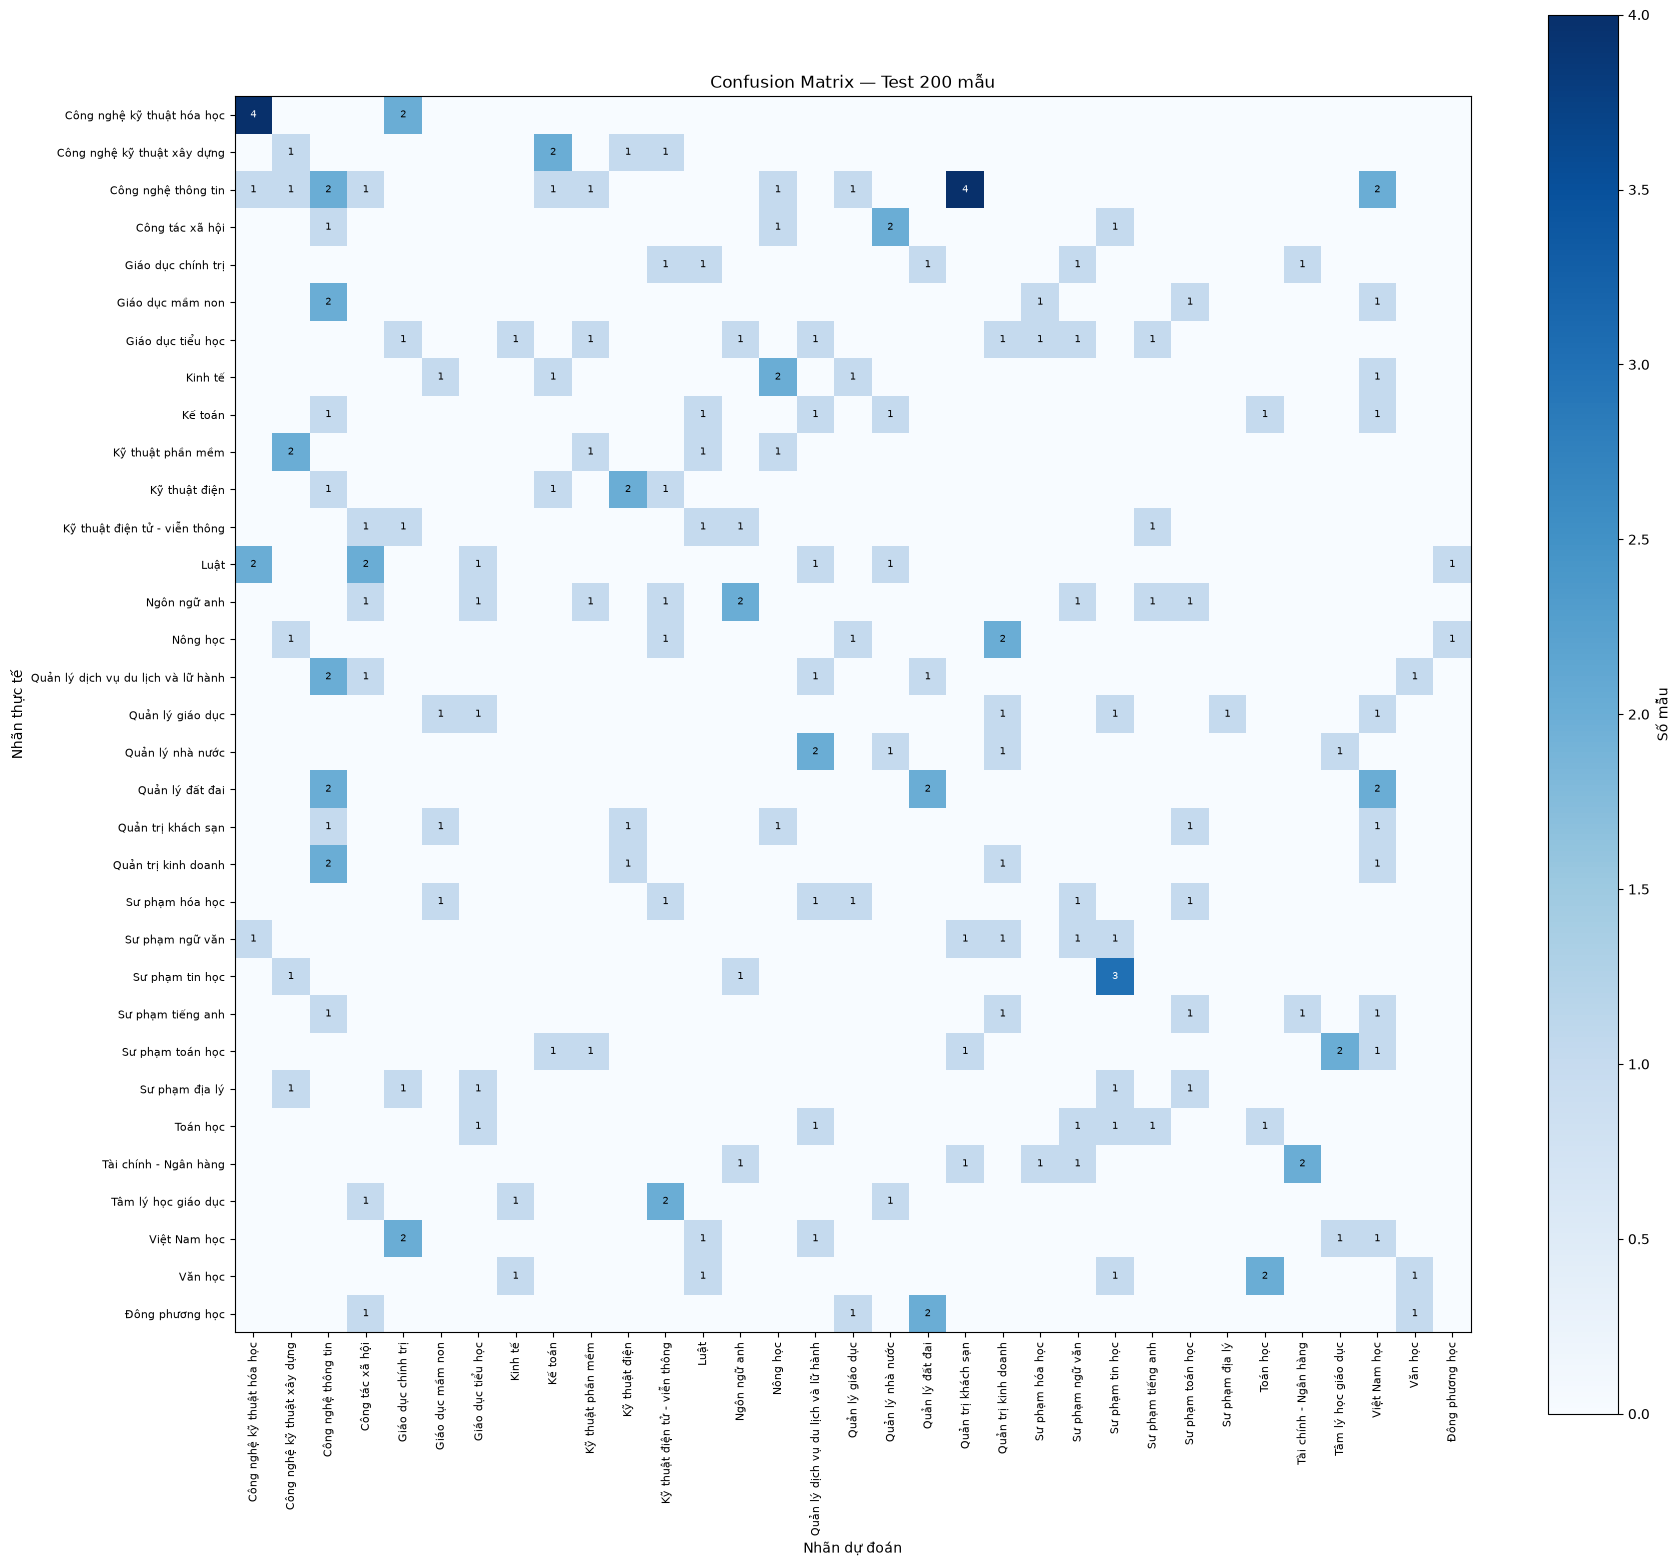

In [4]:
report_dict = classification_report(truth,predictions,labels=classes,
    target_names=classes.tolist(),output_dict=True,zero_division=0)
per_class = pd.DataFrame(report_dict).T.loc[classes,['support','precision','recall','f1-score']]
per_class['support'] = per_class['support'].astype(int)
assert len(per_class) == 33 and per_class['support'].sum() == 200
assert per_class['support'].gt(0).all()
display(per_class.round(4))
cm = confusion_matrix(truth,predictions,labels=classes)
assert cm.shape == (33,33) and cm.sum() == 200
assert np.array_equal(cm.sum(axis=1),per_class['support'])
assert np.trace(cm) == top1_correct.sum()
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize=(18,16))
im = ax.imshow(cm,cmap='Blues',vmin=0)
ax.set_xticks(range(33),classes,rotation=90,fontsize=8)
ax.set_yticks(range(33),classes,fontsize=8)
ax.set(xlabel='Nhãn dự đoán',ylabel='Nhãn thực tế',title='Confusion Matrix — Test 200 mẫu')
for i in range(33):
    for j in range(33):
        if cm[i,j]:
            ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=7,
                    color='white' if cm[i,j]>cm.max()/2 else 'black')
fig.colorbar(im,ax=ax,label='Số mẫu'); plt.tight_layout(); plt.show()


## 7. Minh họa dự đoán Top-3 ẩn danh
54 câu F54 → Pipeline đã fit (scaler Train + classifier) → xác suất 33 nhãn → xếp hạng Top-3.

Minh họa năm dòng đầu theo thứ tự Test đã cố định, không chọn theo kết quả đúng/sai. Tái sử dụng đầu ra đã tính; không gọi fit/predict lại. Chỉ hiển thị nhãn ngành và xác suất, không ID/index gốc, tên, metadata hoặc vector trả lời. Các cột Top-1/2/3 là **3 nhãn ngành được mô hình dự đoán có xác suất cao nhất**; xác suất không là mức phù hợp nghề nghiệp.

In [5]:
example_rows = []
for i in range(5):
    row = {'Ngành thực tế':truth[i]}
    for rank in range(3):
        row[f'Top-{rank+1}'] = top3_labels[i,rank]
        row[f'P{rank+1} (%)'] = round(top3_probabilities[i,rank]*100,2)
    row['Có trong Top-3'] = bool(top3_correct[i])
    example_rows.append(row)
print(pd.DataFrame(example_rows).to_string(index=False))

  Ngành thực tế                              Top-1  P1 (%)                      Top-2  P2 (%)               Top-3  P3 (%)  Có trong Top-3
Sư phạm hóa học      Kỹ thuật điện tử - viễn thông   12.64 Công nghệ kỹ thuật hóa học    9.79      Sư phạm địa lý    9.58           False
Sư phạm hóa học Quản lý dịch vụ du lịch và lữ hành   82.57            Quản lý đất đai    4.06                Luật    3.74           False
Sư phạm hóa học                   Quản lý giáo dục   17.09            Sư phạm hóa học   10.05 Công nghệ thông tin    9.08            True
Sư phạm hóa học                   Sư phạm toán học   34.63             Sư phạm địa lý   13.90       Kỹ thuật điện    7.93           False
Sư phạm hóa học                   Giáo dục mầm non   96.09                       Luật    2.34     Sư phạm ngữ văn    0.71           False


## 8. So sánh CV và Test
Dùng các mean CV đã chốt và cung cấp trong yêu cầu, làm tròn đến 0,01 điểm phần trăm. Test không tham gia chọn cấu hình. Chênh lệch là mô tả; không là lý do chọn lại mô hình.

In [6]:
cv_means = pd.Series({'Accuracy':.1137,'Macro-F1':.1075,
                      'Balanced Accuracy':.1134,'Hit@3':.2762})
comparison = pd.DataFrame({'CV (%)':cv_means*100,'Test (%)':test_metrics*100})
comparison['Test - CV (điểm %)'] = comparison['Test (%)'] - comparison['CV (%)']
display(comparison.round(3))
print('CV fit từng training fold khoảng 639–641 mẫu; mô hình cuối fit 800 mẫu.')
print('Khác biệt cỡ mẫu fit, phân bố của 200 mẫu giữ lại và biến thiên lấy mẫu có thể gây chênh lệch; chưa thể xác định nguyên nhân từ một lần chia.')

CV fit từng training fold khoảng 639–641 mẫu; mô hình cuối fit 800 mẫu.
Khác biệt cỡ mẫu fit, phân bố của 200 mẫu giữ lại và biến thiên lấy mẫu có thể gây chênh lệch; chưa thể xác định nguyên nhân từ một lần chia.


                   CV (%)  Test (%)  Test - CV (điểm %)
Accuracy            11.37    13.000               1.630
Macro-F1            10.75    12.313               1.563
Balanced Accuracy   11.34    13.199               1.859
Hit@3               27.62    28.500               0.880

## 9. Phân tích sai số cuối cùng
Bảng này chỉ mô tả phiên bản đã chốt, không dẫn đến thay đổi mô hình hoặc đặc trưng. “Tốt hơn” là tương đối trong mẫu Test, không là kết luận bền vững ngoài mẫu.

In [7]:
relative_best = per_class.sort_values(['recall','f1-score','support'],ascending=False).head(5)
low_recall = per_class[per_class['recall'] <= .2].sort_values(['recall','support'])
zero_recall = per_class.index[per_class['recall'].eq(0)].tolist()
print('Năm ngành có recall cao nhất trong Test:')
display(relative_best.round(4))
print('Các ngành recall <= 0,2:')
display(low_recall.round(4))
errors = pd.DataFrame([(classes[i],classes[j],int(cm[i,j]))
    for i in range(33) for j in range(33) if i!=j and cm[i,j]>0],
    columns=['Ngành thực tế','Dự đoán nhầm thành','Số mẫu'])
errors = errors.sort_values(['Số mẫu','Ngành thực tế','Dự đoán nhầm thành'],ascending=[False,True,True])
print('Mười cặp nhầm có hướng nhiều nhất:')
display(errors.head(10))
print('Số ngành recall=0:',len(zero_recall))
print('Ngành recall=0:',', '.join(zero_recall))
print('Support nhỏ nhất/lớn nhất:',per_class['support'].min(),per_class['support'].max())
print('Số mẫu không có ngành thực tế trong Top-3:',int((~top3_correct).sum()))
print('PASS: không thay cấu hình; chỉ một fit Pipeline và một bộ dự đoán Test.')

Năm ngành có recall cao nhất trong Test:
Các ngành recall <= 0,2:
Mười cặp nhầm có hướng nhiều nhất:
Số ngành recall=0: 17
Ngành recall=0: Công tác xã hội, Giáo dục chính trị, Giáo dục mầm non, Giáo dục tiểu học, Kinh tế, Kế toán, Kỹ thuật điện tử - viễn thông, Luật, Nông học, Quản lý giáo dục, Quản trị khách sạn, Sư phạm hóa học, Sư phạm tiếng anh, Sư phạm toán học, Sư phạm địa lý, Tâm lý học giáo dục, Đông phương học
Support nhỏ nhất/lớn nhất: 5 15
Số mẫu không có ngành thực tế trong Top-3: 143
PASS: không thay cấu hình; chỉ một fit Pipeline và một bộ dự đoán Test.


                            support  precision  recall  f1-score
Công nghệ kỹ thuật hóa học        6     0.5000  0.6667    0.5714
Sư phạm tin học                   5     0.3333  0.6000    0.4286
Kỹ thuật điện                     5     0.4000  0.4000    0.4000
Tài chính - Ngân hàng             6     0.5000  0.3333    0.4000
Quản lý đất đai                   6     0.3333  0.3333    0.3333

                                    support  precision  recall  f1-score
Công tác xã hội                           5     0.0000  0.0000    0.0000
Giáo dục chính trị                        5     0.0000  0.0000    0.0000
Giáo dục mầm non                          5     0.0000  0.0000    0.0000
Kỹ thuật điện tử - viễn thông             5     0.0000  0.0000    0.0000
Sư phạm tiếng anh                         5     0.0000  0.0000    0.0000
Sư phạm địa lý                            5     0.0000  0.0000    0.0000
Tâm lý học giáo dục                       5     0.0000  0.0000    0.0000
Đông phương học                           5     0.0000  0.0000    0.0000
Kinh tế                                   6     0.0000  0.0000    0.0000
Kế toán                                   6     0.0000  0.0000    0.0000
Nông học                                  6     0.0000  0.0000    0.0000
Quản lý giáo dục                          6     0.0000  0.0000    0.0000
Quản trị khách sạn                        6     0.0

                  Ngành thực tế           Dự đoán nhầm thành  Số mẫu
11          Công nghệ thông tin           Quản trị khách sạn       4
0    Công nghệ kỹ thuật hóa học           Giáo dục chính trị       2
1   Công nghệ kỹ thuật xây dựng                      Kế toán       2
12          Công nghệ thông tin                 Việt Nam học       2
15              Công tác xã hội             Quản lý nhà nước       2
22             Giáo dục mầm non          Công nghệ thông tin       2
37                      Kinh tế                     Nông học       2
46            Kỹ thuật phần mềm  Công nghệ kỹ thuật xây dựng       2
57                         Luật   Công nghệ kỹ thuật hóa học       2
58                         Luật              Công tác xã hội       2

## 10. Kết luận khoa học và hạn chế
Kết quả đo khả năng **phân loại ngành đang học từ 54 câu F54** của một cấu hình đã chọn bằng CV. Đây chưa phải bằng chứng cho mô hình tư vấn ngành nghề phù hợp theo Holland. Chưa có codebook RIASEC hoặc crosswalk xác nhận F54 tương đương Holland 60 câu; chưa có nhãn độc lập xác nhận sinh viên thực sự phù hợp ngành đang học.

CV được dùng chọn mô hình, còn Test giữ lại để đánh giá cuối cùng. Một tập Test nhỏ không xác lập khả năng tổng quát trên quần thể khác; không có hiệu chuẩn xác suất hoặc xác thực bên ngoài. Phân tích sai số không dùng metadata cá nhân và không dẫn đến tuning/refit sau khi xem Test. Các ví dụ chỉ minh họa đầu ra phân loại, không là khuyến nghị nghề nghiệp.

Kiểm chứng: thực thi tuần tự toàn bộ code cell trong tiến trình Python 3.14 mới; bảng và hình nhúng trực tiếp vào notebook. Dùng cách thực thi được cho phép theo lỗi quyền Jupyter Windows đã ghi nhận trước đây; chưa xác nhận qua giao diện/kernel Jupyter. Không lưu model/scaler hoặc tạo file phụ. Không sửa website/API; dừng sau Notebook 07.


### Kết quả thực tế và kết luận ứng dụng
- Train **800 × 54**, Test **200 × 54**, mỗi tập **33 ngành**; index khớp Notebook 02, không giao index/vector. Pipeline fit đúng một lần trên Train, hội tụ; không có ConvergenceWarning.
- Test: Accuracy **0.1300**, Macro-F1 **0.1231**, Balanced Accuracy **0.1320**, Hit@3 **0.2850**.
- Top-1 đúng **26/200**; Top-3 chứa ngành thực tế **57/200**; **143/200** trường hợp vẫn không chứa ngành thực tế trong Top-3.
- Năm ngành recall cao nhất trong mẫu này: **Công nghệ kỹ thuật hóa học, Sư phạm tin học, Kỹ thuật điện, Tài chính - Ngân hàng, Quản lý đất đai**. Xem support, precision và F1 cạnh recall trong phần 9; chưa thể coi đây là những ngành dễ phân loại ổn định trên quần thể.
- Có **17/33 ngành recall=0**, nghĩa là không dự đoán Top-1 đúng mẫu nào của những ngành đó trong Test. Support chỉ **5–15** mẫu/ngành; một mẫu làm recall thay đổi đáng kể, nhất là lớp ít mẫu.
- Chênh Test–CV được báo cáo đầy đủ ở phần 8; không thay đổi cấu hình vì chênh lệch này. Kết quả tuyệt đối còn thấp và phần lớn mẫu không có nhãn thật trong Top-3. **Chưa triển khai mô hình như công cụ tư vấn độc lập.** Chưa có bằng chứng xác thực Holland hoặc nhãn phù hợp nghề nghiệp.
- **7/7 code cell** chạy thành công bằng tiến trình Python 3.14 mới; chưa kiểm chứng qua giao diện/kernel Jupyter. Đã kiểm tra SHA-256 workbook và Notebook 00–06 không đổi trong quá trình chạy. Dừng sau Notebook 07, không tự triển khai.
